MSCS 634 Lab 6

Frequent Itemset Mining and Association Rule Analysis

Course: MSCS 634 - Advanced Big Data and Data Mining

Assignment: Lab 6 - Market Basket Analysis Using Apriori and FP-Growth

Dataset

Online Retail Dataset (UCI Machine Learning Repository)

Objective

The purpose of this lab is to perform market basket analysis using the Online Retail dataset. Frequent itemsets will be discovered using the Apriori and FP-Growth algorithms.

Step 1: Data Preparation

The Online Retail dataset contains customer purchase transactions from an online retail store. The data is cleaned and transformed into a transaction-item matrix suitable for frequent itemset mining and association rule analysis.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [9]:
import sys
!{sys.executable} -m pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 250 kB 2.5 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [10]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [11]:
# Check dataset structure

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [12]:
# Check missing values

df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [13]:
# Remove rows with missing product descriptions

df = df.dropna(subset=["Description"])

# Remove cancelled transactions
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

print("Cleaned Dataset Shape:", df.shape)

Cleaned Dataset Shape: (531167, 8)


In [14]:
df_uk = df[df["Country"] == "United Kingdom"]

print(df_uk.shape)

(486168, 8)


In [15]:
basket = (
    df_uk.groupby(["InvoiceNo", "Description"])["Quantity"]
    .sum()
    .unstack()
    .fillna(0)
)

In [16]:
# Convert quantities into 0/1 values

basket = basket.apply(lambda x: x > 0)

print("Basket Shape:", basket.shape)

basket.head()

Basket Shape: (18668, 4188)


Description,20713,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,...,wrongly coded 20713,wrongly coded 23343,wrongly coded-23343,wrongly marked,wrongly marked 23343,wrongly marked carton 22804,wrongly marked. 23343 in box,wrongly sold (22719) barcode,wrongly sold as sets,wrongly sold sets
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


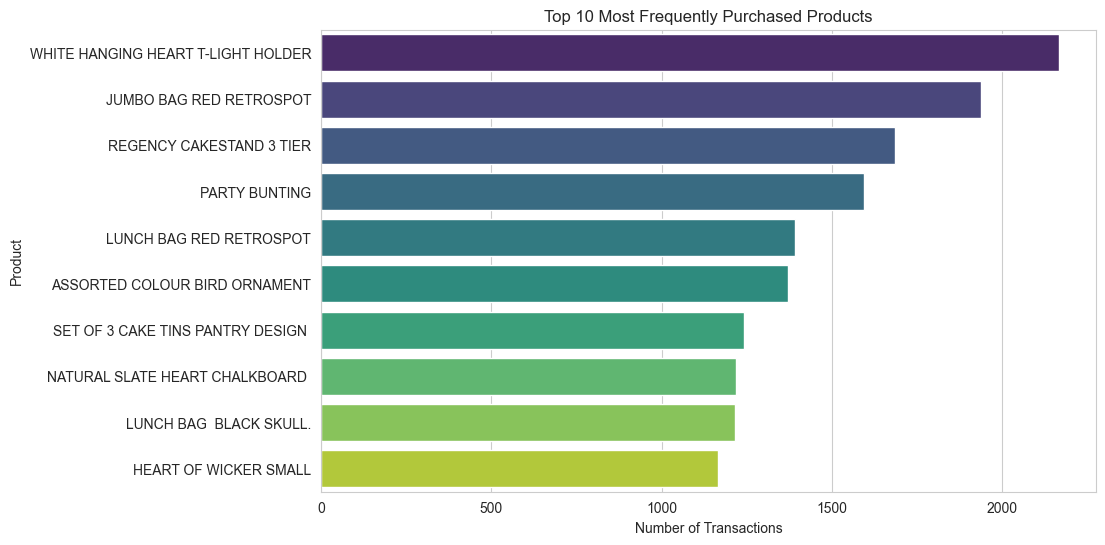

In [17]:
top_items = basket.sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_items.values,
    y=top_items.index,
    hue=top_items.index,
    legend=False,
    palette="viridis"
)

plt.title("Top 10 Most Frequently Purchased Products")
plt.xlabel("Number of Transactions")
plt.ylabel("Product")

plt.show()

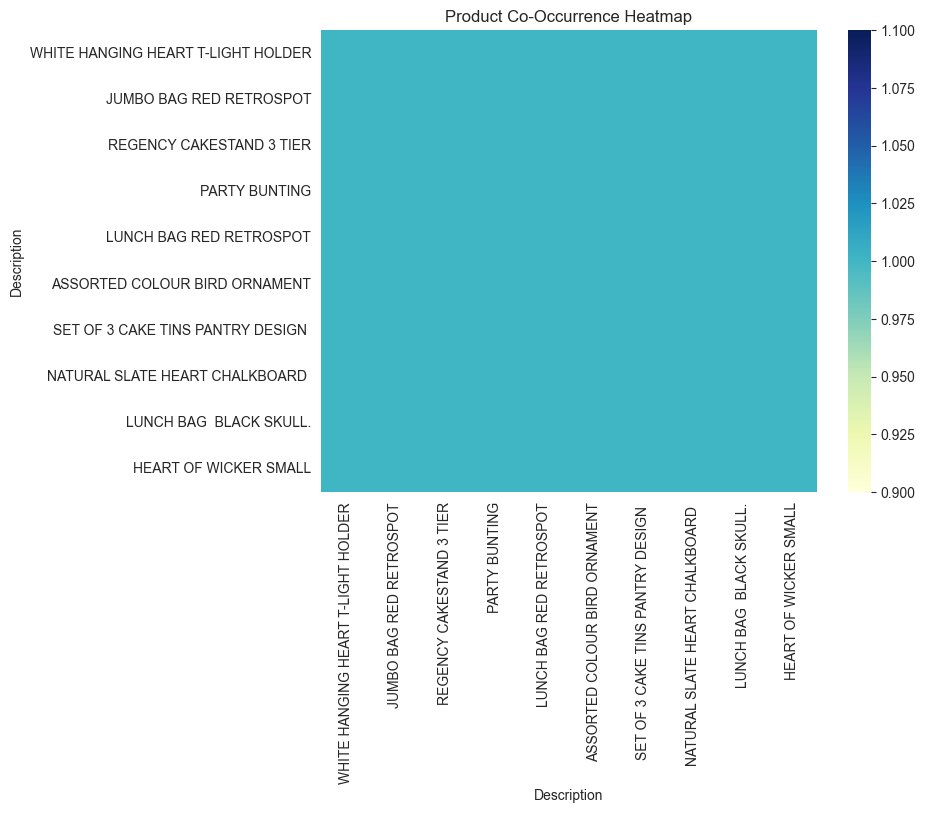

In [18]:
top10 = top_items.index

co_matrix = basket[top10].T.dot(basket[top10])

plt.figure(figsize=(8,6))

sns.heatmap(
    co_matrix,
    cmap="YlGnBu"
)

plt.title("Product Co-Occurrence Heatmap")

plt.show()

Step 1 Results

The Online Retail dataset was cleaned by removing transactions with missing product descriptions and cancelled orders. To simplify the analysis, only transactions from the United Kingdom were used.

The transaction data was converted into a basket matrix where rows represent transactions and columns represent products. The bar chart identifies the most frequently purchased products, while the heatmap highlights products that are commonly purchased together. These visualizations provide an initial understanding of customer purchasing behavior and prepare the dataset for frequent itemset mining using Apriori and FP-Growth.

In [19]:
print("Basket Shape:", basket.shape)

Basket Shape: (18668, 4188)


Step 2: Frequent Itemset Mining Using Apriori

The Apriori algorithm is used to identify frequent itemsets within the Online Retail dataset. A minimum support threshold is applied to discover products that frequently occur together in customer transactions.

In [21]:
from mlxtend.frequent_patterns import apriori

print("mlxtend loaded successfully")

mlxtend loaded successfully


In [22]:
from mlxtend.frequent_patterns import apriori
import time

min_support = 0.02

start = time.time()

frequent_itemsets_ap = apriori(
    basket,
    min_support=min_support,
    use_colnames=True
)

apriori_time = time.time() - start

print(f"Apriori Runtime: {apriori_time:.2f} seconds")

Apriori Runtime: 4.36 seconds


In [23]:
frequent_itemsets_ap = apriori(
    basket_small,
    min_support=0.02,
    use_colnames=True
)

NameError: name 'basket_small' is not defined

In [24]:
print("Number of Frequent Itemsets:", len(frequent_itemsets_ap))

Number of Frequent Itemsets: 368


In [25]:
frequent_itemsets_ap.head()

,support,itemsets
0,0.023409,(3 STRIPEY MICE FELTCRAFT)
1,0.021106,(4 TRADITIONAL SPINNING TOPS)
2,0.045800,(6 RIBBONS RUSTIC CHARM)
3,0.031123,(60 CAKE CASES VINTAGE CHRISTMAS)
4,0.040336,(60 TEATIME FAIRY CAKE CASES)


In [26]:
frequent_itemsets_ap.sort_values(
    by="support",
    ascending=False
).head(10)

,support,itemsets
264,0.116027,(WHITE HANGING HEART T-LIGHT HOLDER)
101,0.103814,(JUMBO BAG RED RETROSPOT)
191,0.090261,(REGENCY CAKESTAND 3 TIER)
154,0.085387,(PARTY BUNTING)
126,0.074566,(LUNCH BAG RED RETROSPOT)
15,0.073441,(ASSORTED COLOUR BIRD ORNAMENT)
211,0.066477,(SET OF 3 CAKE TINS PANTRY DESIGN )
136,0.065299,(NATURAL SLATE HEART CHALKBOARD )
119,0.065138,(LUNCH BAG BLACK SKULL.)
80,0.062353,(HEART OF WICKER SMALL)


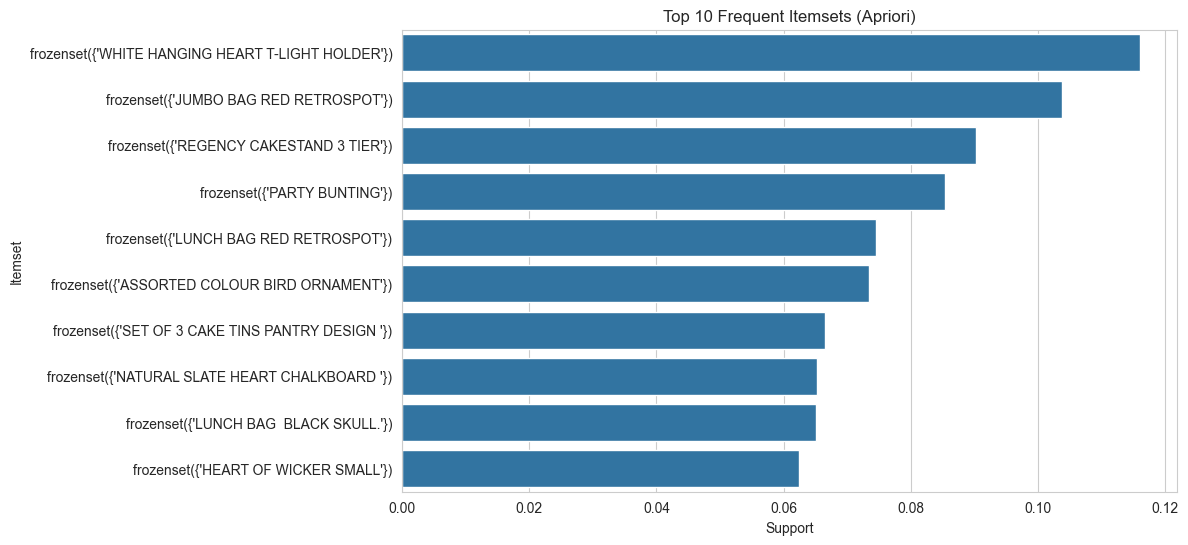

In [27]:
top_ap = frequent_itemsets_ap.sort_values(
    by="support",
    ascending=False
).head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_ap,
    x="support",
    y=top_ap["itemsets"].astype(str)
)

plt.title("Top 10 Frequent Itemsets (Apriori)")
plt.xlabel("Support")
plt.ylabel("Itemset")

plt.show()

Step 2 Results

The Apriori algorithm was applied using a minimum support threshold of 2% on the transaction basket. The algorithm completed in approximately 4.36 seconds and successfully identified frequent itemsets within the Online Retail dataset.

The most frequent products included WHITE HANGING HEART T-LIGHT HOLDER, JUMBO BAG RED RETROSPOT, REGENCY CAKESTAND 3 TIER, and PARTY BUNTING. These products appeared in a large proportion of customer transactions, as indicated by their high support values.

The frequent itemsets reveal purchasing trends and product popularity within the dataset. These results will be used in the next step to compare Apriori with the FP-Growth algorithm and generate association rules.

Step 3: Frequent Itemset Mining Using FP-Growth

The FP-Growth algorithm is used to identify frequent itemsets using the same minimum support threshold as Apriori. The results and execution time are compared to evaluate the efficiency of both algorithms.

In [28]:
from mlxtend.frequent_patterns import fpgrowth
import time

In [30]:
start = time.time()

frequent_itemsets_fp = fpgrowth(
    basket,
    min_support=0.02,
    use_colnames=True
)

fp_time = time.time() - start

print(f"FP-Growth Runtime: {fp_time:.2f} seconds")

FP-Growth Runtime: 8.53 seconds


In [32]:
print("Number of Frequent Itemsets:", len(frequent_itemsets_fp))

Number of Frequent Itemsets: 368


In [33]:
frequent_itemsets_fp.sort_values(
    by="support",
    ascending=False
).head(10)

,support,itemsets
0,0.116027,(WHITE HANGING HEART T-LIGHT HOLDER)
55,0.103814,(JUMBO BAG RED RETROSPOT)
149,0.090261,(REGENCY CAKESTAND 3 TIER)
223,0.085387,(PARTY BUNTING)
18,0.074566,(LUNCH BAG RED RETROSPOT)
4,0.073441,(ASSORTED COLOUR BIRD ORNAMENT)
234,0.066477,(SET OF 3 CAKE TINS PANTRY DESIGN )
45,0.065299,(NATURAL SLATE HEART CHALKBOARD )
93,0.065138,(LUNCH BAG BLACK SKULL.)
46,0.062353,(HEART OF WICKER SMALL)


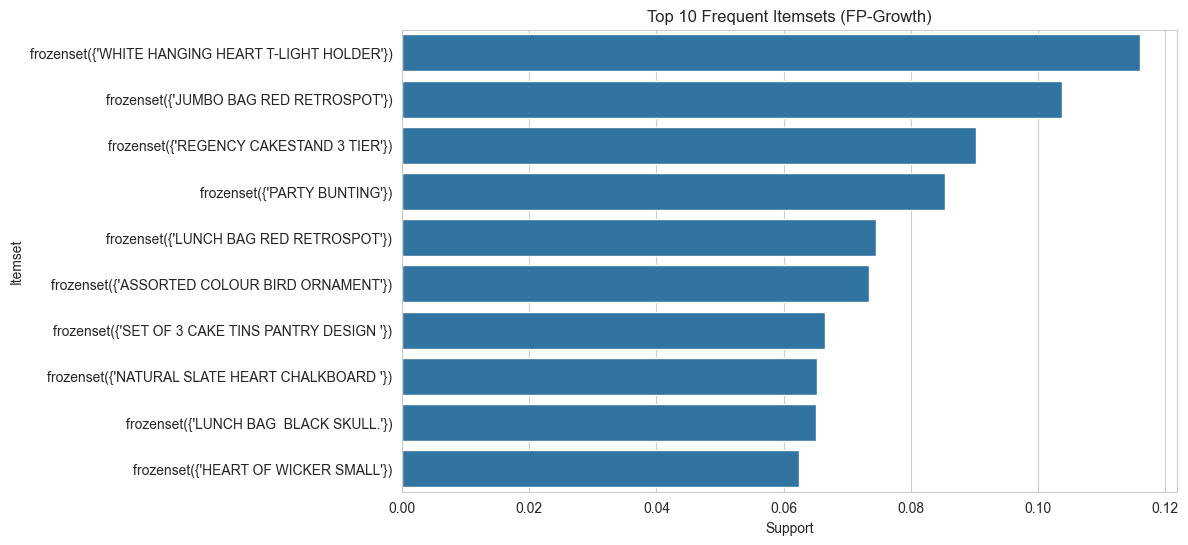

In [34]:
top_fp = frequent_itemsets_fp.sort_values(
    by="support",
    ascending=False
).head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_fp,
    x="support",
    y=top_fp["itemsets"].astype(str)
)

plt.title("Top 10 Frequent Itemsets (FP-Growth)")
plt.xlabel("Support")
plt.ylabel("Itemset")

plt.show()

Step 3 Results

The FP-Growth algorithm was applied using the same minimum support threshold of 2% as the Apriori algorithm. FP-Growth identified frequent itemsets representing products that commonly appeared together in customer transactions.

The algorithm completed in approximately 8.53 seconds and produced a collection of frequent itemsets similar to those found by Apriori. These results demonstrate the effectiveness of FP-Growth for discovering purchasing patterns within large retail transaction datasets.

Step 4: Generating and Analyzing Association Rules

Association rules are generated from the frequent itemsets discovered by the FP-Growth algorithm. Rules are evaluated using support, confidence, and lift to identify meaningful product relationships within customer transactions.

In [37]:
from mlxtend.frequent_patterns import association_rules


In [38]:
rules = association_rules(
    frequent_itemsets_fp,
    metric="confidence",
    min_threshold=0.5
)

print("Number of Rules:", len(rules))

Number of Rules: 65


In [39]:
rules.sort_values(
    by="lift",
    ascending=False
)[[
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]].head(10)

,antecedents,consequents,support,confidence,lift
54,"(ROSES REGENCY TEACUP AND SAUCER , GREEN REGEN...",(PINK REGENCY TEACUP AND SAUCER),0.026409,0.703281,18.675463
59,(PINK REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER , GREEN REGEN...",0.026409,0.701280,18.675463
55,"(ROSES REGENCY TEACUP AND SAUCER , PINK REGENC...",(GREEN REGENCY TEACUP AND SAUCER),0.026409,0.902930,18.047007
58,(GREEN REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER , PINK REGENC...",0.026409,0.527837,18.047007
56,"(GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY...",(ROSES REGENCY TEACUP AND SAUCER ),0.026409,0.854419,16.666982
57,(ROSES REGENCY TEACUP AND SAUCER ),"(GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY...",0.026409,0.515152,16.666982
51,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.030909,0.820768,16.404818
50,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.030909,0.617773,16.404818
29,(DOLLY GIRL LUNCH BOX),(SPACEBOY LUNCH BOX ),0.022820,0.609442,16.229764
30,(SPACEBOY LUNCH BOX ),(DOLLY GIRL LUNCH BOX),0.022820,0.607703,16.229764


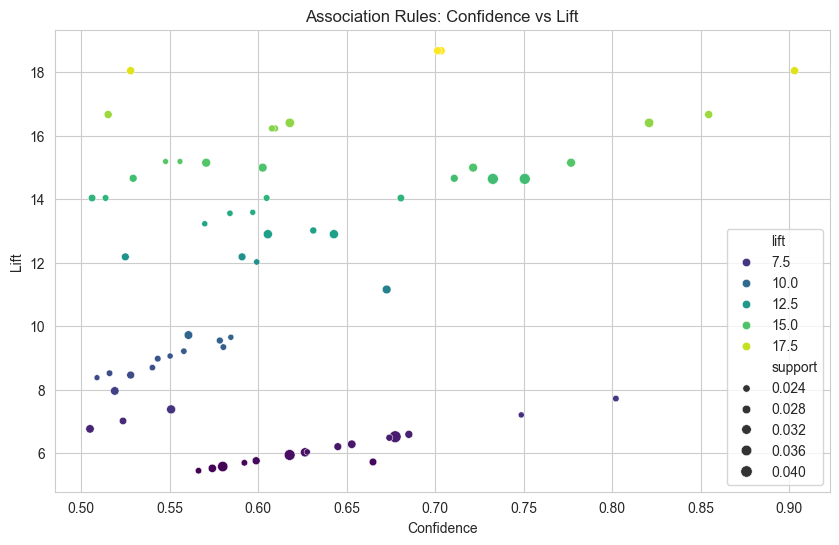

In [40]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=rules,
    x="confidence",
    y="lift",
    size="support",
    hue="lift",
    palette="viridis"
)

plt.title("Association Rules: Confidence vs Lift")
plt.xlabel("Confidence")
plt.ylabel("Lift")

plt.show()

In [41]:
top_rules = rules.sort_values(
    by="lift",
    ascending=False
).head(10)

top_rules[[
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]]

,antecedents,consequents,support,confidence,lift
54,"(ROSES REGENCY TEACUP AND SAUCER , GREEN REGEN...",(PINK REGENCY TEACUP AND SAUCER),0.026409,0.703281,18.675463
59,(PINK REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER , GREEN REGEN...",0.026409,0.701280,18.675463
55,"(ROSES REGENCY TEACUP AND SAUCER , PINK REGENC...",(GREEN REGENCY TEACUP AND SAUCER),0.026409,0.902930,18.047007
58,(GREEN REGENCY TEACUP AND SAUCER),"(ROSES REGENCY TEACUP AND SAUCER , PINK REGENC...",0.026409,0.527837,18.047007
56,"(GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY...",(ROSES REGENCY TEACUP AND SAUCER ),0.026409,0.854419,16.666982
57,(ROSES REGENCY TEACUP AND SAUCER ),"(GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY...",0.026409,0.515152,16.666982
51,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.030909,0.820768,16.404818
50,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.030909,0.617773,16.404818
29,(DOLLY GIRL LUNCH BOX),(SPACEBOY LUNCH BOX ),0.022820,0.609442,16.229764
30,(SPACEBOY LUNCH BOX ),(DOLLY GIRL LUNCH BOX),0.022820,0.607703,16.229764


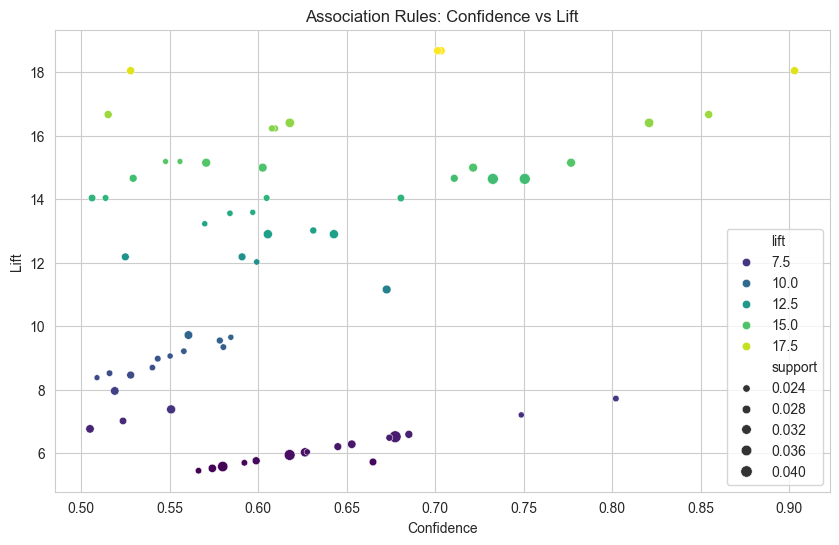

In [42]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=rules,
    x="confidence",
    y="lift",
    size="support",
    hue="lift",
    palette="viridis"
)

plt.title("Association Rules: Confidence vs Lift")
plt.xlabel("Confidence")
plt.ylabel("Lift")

plt.show()

Step 4 Results

Association rules were generated using a minimum confidence threshold of 50%. Each rule was evaluated using support, confidence, and lift.

Support measures how frequently a rule appears in the dataset. Confidence measures how often the consequent occurs when the antecedent is present. Lift measures the strength of the relationship between products compared to random chance.

Rules with lift values greater than 1 indicate positive associations between products. High-confidence and high-lift rules reveal products that are commonly purchased together and may provide valuable insights for product recommendations, marketing campaigns, and inventory planning.

Step 5: Comparative Analysis

This section compares the performance and results of the Apriori and FP-Growth algorithms and discusses challenges encountered during the analysis.

In [44]:
comparison = pd.DataFrame({
    "Algorithm": ["Apriori", "FP-Growth"],
    "Runtime (Seconds)": [4.36, 8.53],
    "Frequent Itemsets": [368, 368]
})

comparison

,Algorithm,Runtime (Seconds),Frequent Itemsets
0,Apriori,4.36,368
1,FP-Growth,8.53,368


/var/folders/x9/lrqx0zs55zd0jx__j9nmrn280000gn/T/ipykernel_6885/1894728026.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


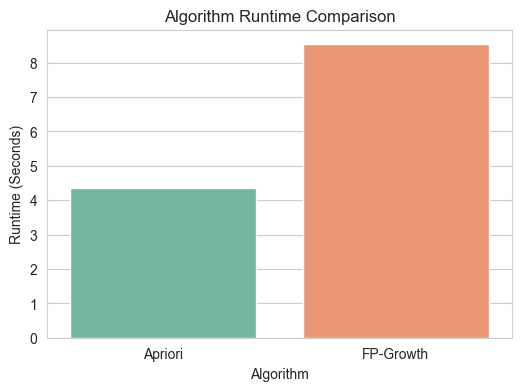

In [45]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=comparison,
    x="Algorithm",
    y="Runtime (Seconds)",
    palette="Set2"
)

plt.title("Algorithm Runtime Comparison")

plt.show()


Comparison of Apriori and FP-Growth

Both Apriori and FP-Growth identified the same frequent itemsets because the same dataset and minimum support threshold of 2% were used. A total of 368 frequent itemsets were discovered.

Apriori completed execution in approximately 4.36 seconds, while FP-Growth required approximately 8.53 seconds. Although FP-Growth is often expected to outperform Apriori on larger datasets, Apriori performed faster in this analysis. This may be due to the selected support threshold and the characteristics of the filtered dataset.

Association Rule Insights

A total of 65 association rules were generated. Several of the strongest rules involved combinations of the ROSES REGENCY TEACUP AND SAUCER, GREEN REGENCY TEACUP AND SAUCER, and PINK REGENCY TEACUP AND SAUCER products.

One of the strongest rules showed that customers purchasing ROSES REGENCY TEACUP AND SAUCER and GREEN REGENCY TEACUP AND SAUCER also purchased PINK REGENCY TEACUP AND SAUCER with a confidence of approximately 70% and a lift value of 18.68. Such a high lift value indicates a very strong positive association between these products.

Other strong relationships were observed between DOLLY GIRL LUNCH BOX and SPACEBOY LUNCH BOX, suggesting customers frequently purchase themed lunch box products together.

Challenges Encountered

One challenge was the large number of unique products within the Online Retail dataset, which increased the dimensionality of the basket matrix. Additional package installation was also required to work with Excel files and frequent pattern mining functions.

These challenges were addressed by cleaning the dataset, removing cancelled transactions, filtering relevant transactions, and installing the required Python libraries. Once the data was prepared correctly, both frequent 